In [1]:
import pandas as pd 
import numpy as np 
from pathlib import Path 
import seaborn as sns 
import matplotlib.pyplot as plt 
import sys


In [2]:
BASE_DIR = Path.cwd().resolve().parent
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))
# import all cleaning functions 
from src.cleaning import clean_reactor, clean_operator, clean_lot_name, clean_unit_name, remove_duplicates, fill_pressure_unit, fill_temp_unit, clean_temp_pressure, clean_outliers

In [3]:
raw_data = pd.read_parquet(BASE_DIR / "data" / "raw" / "batch_readings.parquet")

In [4]:
raw_data.head()

,batch_id,timestamp,reactor_id,temp_c,pressure_bar,agitator_rpm,feed_rate,feed_purity,catalyst_lot,ph,operator_shift,ambient_humidity,yield_pct,temp_unit,pressure_unit
0,0,2022-01-01 00:52:00,Reactor 5,24.688933,0.988253,117.363277,50.401075,0.963375,L119,6.585012,A,54.050379,59.521627,degC,bar
1,0,2022-01-01 00:53:00,R5,78.129361,0.989035,110.259602,50.823903,0.963375,L119,6.652077,A,54.050379,59.521627,F,NaN
2,0,2022-01-01 00:54:00,R5,29.354209,1.001850,113.898923,51.681363,0.963375,L119,6.668752,A,54.050379,59.521627,c,BAR
3,0,2022-01-01 00:55:00,R5,32.377277,1.115178,115.309385,51.026732,0.963375,L119,6.590493,A,54.050379,59.521627,C,NaN
4,0,2022-01-01 00:56:00,R5,32.307078,1.125136,123.293666,50.495019,0.963375,L119,6.609744,A,54.050379,59.521627,degC,BAR


In [5]:
raw_data_clean = raw_data.copy()

In [6]:
# create a cleaning function 
def clean_data(data):
    data = clean_reactor(data)
    data = clean_operator(data)
    data = clean_lot_name(data)
    data = clean_unit_name(data)
    data = remove_duplicates(data)
    data = fill_pressure_unit(data)
    data = fill_temp_unit(data)
    data = clean_temp_pressure(data)
    data = clean_outliers(data)

    return data

cleaned_batch_data = clean_data(raw_data_clean)

In [7]:
cleaned_batch_data.shape

(1999980, 15)

In [8]:
raw_data.shape

(2009978, 15)

In [9]:
cleaned_batch_data.head(10)

,batch_id,timestamp,reactor_id,temp_c,pressure_bar,agitator_rpm,feed_rate,feed_purity,catalyst_lot,ph,operator_shift,ambient_humidity,yield_pct,temp_unit,pressure_unit
0,0,2022-01-01 00:52:00,R5,24.688933,0.988253,117.363277,50.401075,0.963375,LOT-119,6.585012,A,54.050379,59.521627,°C,bar
1,0,2022-01-01 00:53:00,R5,25.627423,0.989035,110.259602,50.823903,0.963375,LOT-119,6.652077,A,54.050379,59.521627,°C,bar
2,0,2022-01-01 00:54:00,R5,29.354209,1.001850,113.898923,51.681363,0.963375,LOT-119,6.668752,A,54.050379,59.521627,°C,bar
3,0,2022-01-01 00:55:00,R5,32.377277,1.115178,115.309385,51.026732,0.963375,LOT-119,6.590493,A,54.050379,59.521627,°C,bar
4,0,2022-01-01 00:56:00,R5,32.307078,1.125136,123.293666,50.495019,0.963375,LOT-119,6.609744,A,54.050379,59.521627,°C,bar
5,0,2022-01-01 00:57:00,R5,33.076098,1.148186,126.507262,50.699760,0.963375,LOT-119,6.657038,A,54.050379,59.521627,°C,bar
6,0,2022-01-01 00:58:00,R5,33.164814,1.104675,116.574943,49.926178,0.963375,LOT-119,6.613868,A,54.050379,59.521627,°C,bar
7,0,2022-01-01 00:59:00,R5,35.399471,1.140843,118.525533,50.226931,0.963375,LOT-119,6.665979,A,54.050379,59.521627,°C,bar
8,0,2022-01-01 01:00:00,R5,39.497618,1.235249,121.010352,50.303870,0.963375,LOT-119,6.585807,A,54.050379,59.521627,°C,bar
9,0,2022-01-01 01:01:00,R5,38.891914,1.235696,111.388008,50.382383,0.963375,LOT-119,6.561605,A,54.050379,59.521627,°C,bar


In [10]:
cleaned_batch_data.to_parquet(BASE_DIR / "data" / "processed" / "cleaned_batch_readings.parquet", index=False)

In [3]:
cleaned_data = pd.read_parquet(BASE_DIR / "data" / 'processed' / "cleaned_batch_readings.parquet")

In [12]:
# get the months and get the group by for the months for temperature, pressure
cleaned_data['month'] = pd.to_datetime(cleaned_data['timestamp']).dt.month
# groupby_month = cleaned_batch_data.groupby()

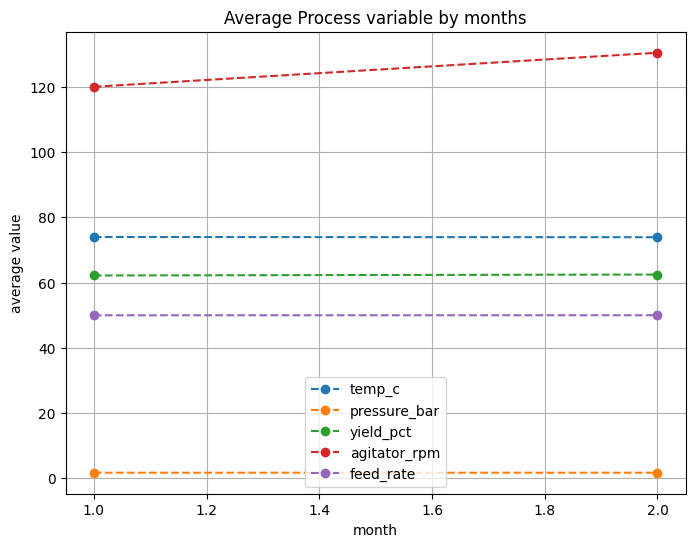

In [13]:
groupby_months = cleaned_data.groupby("month")[['temp_c', 'pressure_bar', 'yield_pct', 'agitator_rpm', 'feed_rate']].mean()
groupby_months.plot(
    linestyle='--',
    marker='o', 
    figsize=(8, 6)
)
plt.title("Average Process variable by months")
plt.ylabel("average value")
plt.grid()
plt.savefig("../docs/09_change_values_time")
plt.show()

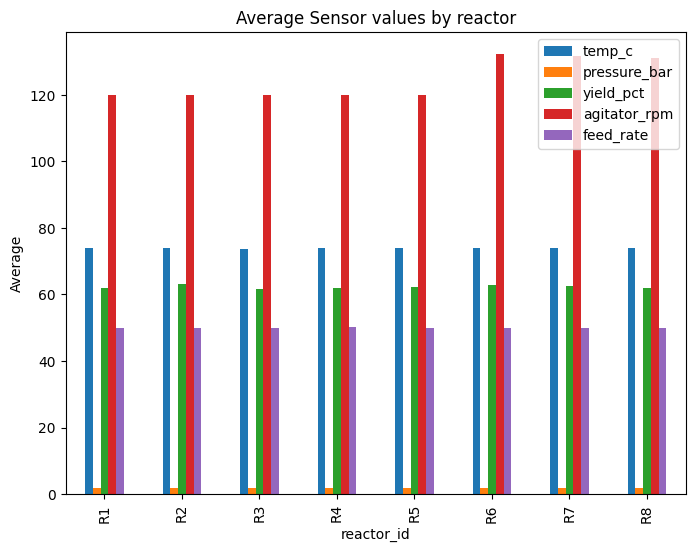

In [14]:
reactor_summary = cleaned_data.groupby('reactor_id')[['temp_c', 'pressure_bar', 'yield_pct', 'agitator_rpm', 'feed_rate']].mean()
reactor_summary.plot(
    kind='bar',
    figsize=(8, 6)
)
plt.title("Average Sensor values by reactor")
plt.ylabel("Average")
plt.savefig("../docs/average_values_per_reactor.png")
plt.show()

In [15]:
cleaned_data.isna().sum().to_csv("../docs/missing_values.csv")


In [16]:
# group the data by batch and get the yield lower than zero for each batch 
groupby_batch = cleaned_data.groupby("batch_id")['yield_pct'].apply(lambda x: (x == 0).sum())
groupby_batch

batch_id
0          0
1          0
2          0
3          0
4          0
        ... 
11106      0
11107      0
11108      0
11109    180
11110      0
Name: yield_pct, Length: 11111, dtype: int64

In [17]:
filter_data = groupby_batch[groupby_batch > 0]
filter_data
filter_data.to_csv("../docs/filter_data_yield_zero.csv")

In [4]:
# filter of all rows with yield
filtered_data = cleaned_data[cleaned_data['yield_pct'] > 0].copy()

In [6]:
filtered_data.info()

<class 'pandas.DataFrame'>
Index: 1981080 entries, 0 to 1999979
Data columns (total 15 columns):
 #   Column            Dtype         
---  ------            -----         
 0   batch_id          int64         
 1   timestamp         datetime64[us]
 2   reactor_id        str           
 3   temp_c            float64       
 4   pressure_bar      float64       
 5   agitator_rpm      float64       
 6   feed_rate         float64       
 7   feed_purity       float64       
 8   catalyst_lot      str           
 9   ph                float64       
 10  operator_shift    str           
 11  ambient_humidity  float64       
 12  yield_pct         float64       
 13  temp_unit         str           
 14  pressure_unit     str           
dtypes: datetime64[us](1), float64(8), int64(1), str(5)
memory usage: 275.2 MB


In [7]:
filter_data  = filtered_data.groupby("batch_id")['yield_pct'].apply(lambda x : (x == 0).sum())
filter_data
print(filtered_data['ambient_humidity'].max())
print(filtered_data['feed_purity'].max())
print(filtered_data['ambient_humidity'].min())
print(filtered_data['feed_purity'].min())

87.45431345395293
100.0
22.562323924150295
0.91299112740934


In [9]:
def fraction_unknow(x):
    return x.isna().mean()

def get_quantille_05(x):
    return x.quantile(0.05)

def get_quantille_90(x):
    return x.quantile(0.95)

aggr_results = {
    "reactor_id" :"first",
    "operator_shift" : "first",
    "feed_purity" : "first",
    "catalyst_lot" : "first",
    "timestamp" : "min",
    'yield_pct' : "first",
    "ambient_humidity" : "first"
}

sensor_result = ['temp_c', "pressure_bar", "agitator_rpm", "feed_rate", "ph"]
for sensor in sensor_result:
    aggr_results[sensor] = ['mean', 'std', 'min', 'max', fraction_unknow, get_quantille_05, get_quantille_90]

batch_reactor = filtered_data.groupby("batch_id").agg(aggr_results)

new_cols_name = []
for col in batch_reactor.columns:
    if col[1] in ['first']:
        new_cols_name.append(col[0])
    elif  col[0] == "timestamp" and col[1] == "min":
        new_cols_name.append("batch_start")
    else:
        new_cols_name.append(f"{col[0]}_{col[1]}")

batch_reactor.columns = new_cols_name
batch_reactor = batch_reactor.reset_index()

display(batch_reactor.head())

,batch_id,reactor_id,operator_shift,feed_purity,catalyst_lot,batch_start,yield_pct,ambient_humidity,temp_c_mean,temp_c_std,...,feed_rate_fraction_unknow,feed_rate_get_quantille_05,feed_rate_get_quantille_90,ph_mean,ph_std,ph_min,ph_max,ph_fraction_unknow,ph_get_quantille_05,ph_get_quantille_90
0,0,R5,A,0.963375,LOT-119,2022-01-01 00:52:00,59.521627,54.050379,70.830789,12.520624,...,0.050000,49.923121,51.566892,6.437876,0.115852,6.176987,6.676187,0.033333,6.262175,6.622747
1,1,R7,A,0.962882,LOT-002,2022-01-01 01:25:00,69.576301,52.904138,73.444318,13.847610,...,0.022222,48.353880,50.017927,7.150818,0.109881,6.939894,7.392830,0.033333,6.985752,7.327390
2,2,R2,A,0.959922,LOT-119,2022-01-01 00:27:00,54.799699,51.992843,70.433695,12.120622,...,0.022222,51.052669,52.528677,6.763659,0.114753,6.450911,7.043655,0.038889,6.585890,6.947063
3,3,R3,B,0.965263,LOT-003,2022-01-01 00:47:00,43.799610,59.895421,77.007976,13.874411,...,0.050000,48.355655,50.036517,6.427968,0.116073,6.177925,6.716607,0.027778,6.229723,6.629469
4,4,R8,NIGHT,0.987677,LOT-061,2022-01-01 01:59:00,58.296184,47.522894,66.749413,11.242480,...,0.050000,52.107783,53.583611,6.942626,0.125743,6.631501,7.197336,0.033333,6.749315,7.158225


In [10]:
batch_reactor.shape

(11006, 43)

In [11]:
batch_reactor.to_parquet("../data/processed/batch_reactor_data.parquet", index=False)

In [12]:
batch_reactor.describe()

,batch_id,feed_purity,batch_start,yield_pct,ambient_humidity,temp_c_mean,temp_c_std,temp_c_min,temp_c_max,temp_c_fraction_unknow,...,feed_rate_fraction_unknow,feed_rate_get_quantille_05,feed_rate_get_quantille_90,ph_mean,ph_std,ph_min,ph_max,ph_fraction_unknow,ph_get_quantille_05,ph_get_quantille_90
count,11006.000000,11006.000000,11006,11006.000000,11006.000000,10979.000000,10978.000000,10979.000000,10979.000000,11006.000000,...,11006.000000,10985.000000,10985.000000,10990.000000,10990.000000,10990.000000,10990.000000,11006.000000,10990.000000,10990.000000
mean,5552.400145,4.706400,2022-01-28 00:32:36.203888,62.894180,55.065085,73.817800,13.580158,18.519404,96.835620,0.044731,...,0.042665,49.174254,50.790111,6.914494,0.115140,6.657037,7.171711,0.042059,6.733014,7.095670
min,0.000000,0.912991,2022-01-01 00:27:00,0.230208,22.562324,31.133236,0.703405,-272.456326,37.664434,0.000000,...,0.000000,41.597692,43.391956,6.124952,0.000005,5.869324,6.270122,0.000000,5.942785,6.258450
25%,2768.250000,0.960376,2022-01-14 11:32:45,52.266065,41.675049,70.985196,12.492004,23.856081,82.996236,0.027778,...,0.027778,47.792296,49.417334,6.776655,0.112904,6.517998,7.032774,0.027778,6.595371,6.957796
50%,5552.500000,0.970768,2022-01-28 00:17:30,64.770439,55.234559,73.913554,13.301954,24.988517,87.353809,0.038889,...,0.038889,49.190117,50.811672,6.914988,0.115498,6.658663,7.172096,0.038889,6.734438,7.096640
75%,8331.750000,0.981270,2022-02-10 12:53:45,75.248009,68.472652,76.777943,14.152311,26.095803,98.520452,0.050000,...,0.050000,50.533105,52.147748,7.052717,0.117946,6.795677,7.310145,0.050000,6.870919,7.233315
max,11110.000000,100.000000,2022-02-24 01:41:00,97.302718,87.454313,91.541760,36.349843,85.646464,299.231008,1.000000,...,1.000000,57.004834,58.699804,7.662654,0.192050,7.517522,7.927774,1.000000,7.550755,7.847578
std,3209.261880,18.579068,NaN,15.588711,14.657286,4.306927,2.325084,35.412744,26.246203,0.066096,...,0.058401,2.021388,2.020143,0.206213,0.006535,0.208584,0.207816,0.056158,0.206672,0.206309
